# Практическая работа №7. От тензоров PyTorch к классификации изображений

**Дицель Н.С., ИКБО-11-23.** Проверил: ст. преподаватель Приходько Н.А. Дата: 07.11.2026.

Цель: проверить операции PyTorch и шаг обучения, обучить MNIST, сравнить линейную модель с CNN на BloodMNIST, выполнить CIFAR-10 для трёх классов.

Работа выполняется сверху вниз. Для всех классификаторов — пять эпох, seed=42; итоговый test считается с параметрами пятой эпохи, как требует методичка. Краткие выводы сопровождают расчёты. Полные вопросы и короткие ответы — в отдельном файле «Ответы_на_вопросы_7.md».

## 1. Окружение

In [1]:
from pathlib import Path
from time import perf_counter
import json, platform, random, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torchvision
from torch import nn, optim
from torch.utils.data import Dataset, DataLoader, TensorDataset, random_split
from torchvision import datasets, transforms
from torchvision.datasets.utils import download_url
from PIL import Image
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display

ROOT=Path.cwd()
if not (ROOT/"Практическая работа №7.docx").exists():
    ROOT=ROOT/"Практическая работа №7"
assert (ROOT/"Практическая работа №7.docx").exists(),ROOT
DATA=ROOT/"practice7_data";OUT=ROOT/"practice7_results"
DATA.mkdir(exist_ok=True);OUT.mkdir(exist_ok=True)
SEED=42
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
torch.set_num_threads(2)
torch.set_printoptions(precision=3,sci_mode=False)
device=torch.device("cuda" if torch.cuda.is_available() else
    "mps" if torch.backends.mps.is_available() else "cpu")
if device.type=="cuda":
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic=True
    torch.backends.cudnn.benchmark=False
plt.rcParams.update({"font.family":"DejaVu Sans","figure.dpi":100})
environment=dict(python=platform.python_version(),torch=torch.__version__,
    torchvision=torchvision.__version__,numpy=np.__version__,device=str(device),
    cpu_threads=torch.get_num_threads(),seed=SEED)
print(environment)
(OUT/"environment.json").write_text(json.dumps(environment,indent=2),encoding="utf-8")
def savefig(name):
    plt.gcf().savefig(OUT/name,dpi=160,bbox_inches="tight")
    plt.show()
def params(model):return sum(p.numel() for p in model.parameters() if p.requires_grad)

{'python': '3.12.10', 'torch': '2.15.0+cpu', 'torchvision': '0.29.2+cpu', 'numpy': '2.5.4', 'device': 'cpu', 'cpu_threads': 2, 'seed': 42}


## 2. Тензоры, Linear и один шаг обучения

Проверяем формы, общую память NumPy, матричное умножение и градиенты на малых примерах.

In [2]:
a=np.arange(1,7,dtype=np.float32).reshape(2,3)
x=torch.tensor(a)
assert np.allclose(a*2+1,(x*2+1).numpy())
print("Форма/оси/элементы:",x.shape,x.ndim,x.numel(),x.dtype,x.device)
print("Второй столбец:",x[:,1],"Средние столбцов:",x.mean(0),"строк:",x.mean(1))
print("Broadcasting:",x+torch.tensor([10.,20.,30.]))
a2=torch.tensor([[1.,2.],[3.,4.]]);b2=torch.tensor([[5.,6.],[7.,8.]])
print("*:",a2*b2,"@:",a2@b2)
image_hwc=torch.arange(18).reshape(2,3,3)
image_chw=image_hwc.permute(2,0,1)
batch=image_chw.unsqueeze(0)
print("HWC → CHW → NCHW:",image_hwc.shape,image_chw.shape,batch.shape)
assert not torch.equal(image_chw,image_hwc.reshape(3,2,3))
print("Flatten сохраняет пакет:",batch.flatten(1).shape)
shared=torch.from_numpy(a);copied=shared.clone();a[0,0]=100
assert shared[0,0]==100 and copied[0,0]==1
print("from_numpy делит память; clone создаёт независимую копию.")

Форма/оси/элементы: torch.Size([2, 3]) 2 6 torch.float32 cpu
Второй столбец: tensor([2., 5.]) Средние столбцов: tensor([2.500, 3.500, 4.500]) строк: tensor([2., 5.])
Broadcasting: tensor([[11., 22., 33.],
        [14., 25., 36.]])
*: tensor([[ 5., 12.],
        [21., 32.]]) @: tensor([[19., 22.],
        [43., 50.]])
HWC → CHW → NCHW: torch.Size([2, 3, 3]) torch.Size([3, 2, 3]) torch.Size([1, 3, 2, 3])
Flatten сохраняет пакет: torch.Size([1, 18])
from_numpy делит память; clone создаёт независимую копию.


In [3]:
x = torch.tensor([2., 3., 4.])
w = torch.tensor([0.5, -1., 2.])
b = torch.tensor(1.)

contributions = x * w
print("Вклады признаков", contributions)
print("Ответ", contributions.sum() + b)
print("Тот же ответ через @", x @ w + b)

X = torch.tensor([[2., 3., 4.], [1., 0., 2.]])
W = torch.tensor([[0.5, -1., 2.], [1., 1., -0.5]])
b = torch.tensor([1., -2.])

Y_manual = X @ W.T + b
print("X", X.shape, "W.T", W.T.shape, "Y", Y_manual.shape)
print(Y_manual)

layer = nn.Linear(in_features=3, out_features=2)
with torch.no_grad():
    layer.weight.copy_(W)
    layer.bias.copy_(b)

Y_layer = layer(X)
print("Ответ слоя\n", Y_layer)
print("Совпадает с ручным расчётом", torch.allclose(Y_manual, Y_layer))
print("Веса", layer.weight.shape, "Смещения", layer.bias.shape)

for name, parameter in layer.named_parameters():
    print(name, tuple(parameter.shape),
          "чисел", parameter.numel(),
          "requires_grad", parameter.requires_grad)

print("Всего параметров", sum(p.numel() for p in layer.parameters()))
assert torch.allclose(Y_manual,Y_layer)
assert params(layer)==8
print("Число параметров не зависит от размера пакета.")

Вклады признаков tensor([ 1., -3.,  8.])
Ответ tensor(7.)
Тот же ответ через @ tensor(7.)
X torch.Size([2, 3]) W.T torch.Size([3, 2]) Y torch.Size([2, 2])
tensor([[ 7.000,  1.000],
        [ 5.500, -2.000]])
Ответ слоя
 tensor([[ 7.000,  1.000],
        [ 5.500, -2.000]], grad_fn=<AddmmBackward0>)
Совпадает с ручным расчётом True
Веса torch.Size([2, 3]) Смещения torch.Size([2])
weight (2, 3) чисел 6 requires_grad True
bias (2,) чисел 2 requires_grad True
Всего параметров 8
Число параметров не зависит от размера пакета.


**Вывод:** Linear вычисляет XWᵀ+b; восемь параметров — шесть весов и два смещения. Перестановка осей через permute сохраняет каналы, reshape этого не гарантирует.

In [4]:
rows = []
for side in [28, 128, 512]:
    inputs = 3 * side * side
    parameters = inputs * 64 + 64
    rows.append([side, inputs, parameters,
                 10000 * inputs * 4 / 1024**2,
                 parameters * 4 / 1024**2])

pd.DataFrame(rows, columns=[
    "Сторона RGB", "Входных чисел", "Параметров Linear",
    "10 000 изображений, MiB", "Параметры, MiB"
]).round(2)

,Сторона RGB,Входных чисел,Параметров Linear,"10 000 изображений, MiB","Параметры, MiB"
0,28,2352,150592,89.72,0.57
1,128,49152,3145792,1875.00,12.00
2,512,786432,50331712,30000.00,192.00


**Вывод:** у полносвязного слоя число весов быстро растёт с площадью изображения. Таблица оценивает только пиксели и веса float32; обучение дополнительно хранит градиенты и промежуточные значения.

In [5]:
torch.manual_seed(7)
X = torch.tensor([[1., -2.], [0., 3.]])
first = nn.Linear(2, 4)
activation = nn.ReLU()
last = nn.Linear(4, 1)

z = first(X)
h = activation(z)
y_manual = last(h)
model = nn.Sequential(first, activation, last)

print("После первого слоя\n", z)
print("После ReLU\n", h)
print("Ответ\n", model(X))

current = X
for number, step in enumerate(model):
    current = step(current)
    print(number, type(step).__name__, tuple(current.shape))

print("Параметры всей последовательности",
      sum(p.numel() for p in model.parameters()))

torch.manual_seed(7)
first = nn.Linear(2, 3)
second = nn.Linear(3, 1)
X = torch.tensor([[1., -2.], [0., 3.]])

W_total = second.weight @ first.weight
b_total = second.weight @ first.bias + second.bias
separate = second(first(X))
combined = X @ W_total.T + b_total

print("Два слоя\n", separate)
print("Одна формула\n", combined)
assert torch.allclose(separate,combined,atol=1e-6)
print("Два слоя без активации сворачиваются в один; ReLU добавляет нелинейность.")

После первого слоя
 tensor([[ 0.711,  0.278,  0.336, -0.709],
        [-1.468,  1.162,  0.184,  0.622]], grad_fn=<AddmmBackward0>)
После ReLU
 tensor([[0.711, 0.278, 0.336, 0.000],
        [0.000, 1.162, 0.184, 0.622]], grad_fn=<ReluBackward0>)
Ответ
 tensor([[-0.031],
        [-0.219]], grad_fn=<AddmmBackward0>)
0 Linear (2, 4)
1 ReLU (2, 4)
2 Linear (2, 1)
Параметры всей последовательности 17
Два слоя
 tensor([[-0.084],
        [-0.614]], grad_fn=<AddmmBackward0>)
Одна формула
 tensor([[-0.084],
        [-0.614]], grad_fn=<AddBackward0>)
Два слоя без активации сворачиваются в один; ReLU добавляет нелинейность.


In [6]:
x = torch.tensor([[1.], [2.], [3.]])
y = torch.tensor([[3.], [5.], [7.]])
regression = nn.Sequential(nn.Linear(1, 1))
with torch.no_grad():
    regression[0].weight.zero_()
    regression[0].bias.zero_()

loss_function = nn.MSELoss()
optimizer = optim.SGD(regression.parameters(), lr=0.1)
optimizer.zero_grad()
prediction = regression(x)
loss = loss_function(prediction, y)

print("Предсказания", prediction.flatten())
print("Ошибка вручную", ((prediction - y) ** 2).mean().item())
print("MSELoss", loss.item())

loss.backward()
manual_dw = (2 * (prediction.detach() - y) * x).mean()
manual_db = (2 * (prediction.detach() - y)).mean()

print("dw вручную", manual_dw.item())
print("dw от PyTorch", regression[0].weight.grad.item())
print("db вручную", manual_db.item())
print("db от PyTorch", regression[0].bias.grad.item())
print("Вес пока прежний", regression[0].weight.item())

w_before = regression[0].weight.detach().clone()
b_before = regression[0].bias.detach().clone()
w_expected = w_before - 0.1 * regression[0].weight.grad
b_expected = b_before - 0.1 * regression[0].bias.grad

optimizer.step()
with torch.no_grad():
    new_loss = loss_function(regression(x), y)

print("Новый вес", regression[0].weight.item())
print("Новое смещение", regression[0].bias.item())
print("Ошибка до", loss.item(), "после", new_loss.item())

a = torch.tensor(3., requires_grad=True)
(a ** 2).backward()
print("После первого вычисления", a.grad.item())
(a ** 2).backward()
print("После второго без очистки", a.grad.item())
a.grad.zero_()
(a ** 2).backward()
print("После очистки и нового вычисления", a.grad.item())
assert torch.allclose(regression[0].weight,w_expected)
assert torch.allclose(regression[0].bias,b_expected)
assert torch.allclose(manual_dw,torch.tensor(-22.666666),atol=1e-5)
assert new_loss.item()<loss.item()

Предсказания tensor([0., 0., 0.], grad_fn=<ViewBackward0>)
Ошибка вручную 27.66666603088379
MSELoss 27.66666603088379
dw вручную -22.66666603088379
dw от PyTorch -22.666667938232422
db вручную -10.0
db от PyTorch -10.0
Вес пока прежний 0.0
Новый вес 2.266666889190674
Новое смещение 1.0
Ошибка до 27.66666603088379 после 0.33185240626335144
После первого вычисления 6.0
После второго без очистки 12.0
После очистки и нового вычисления 6.0


**Вывод:** zero_grad очищает накопленные градиенты, backward вычисляет производные, step меняет параметры. Ручной расчёт совпал с PyTorch, после шага MSE уменьшилась.

MSE после обучения

 0.0015070948284119368


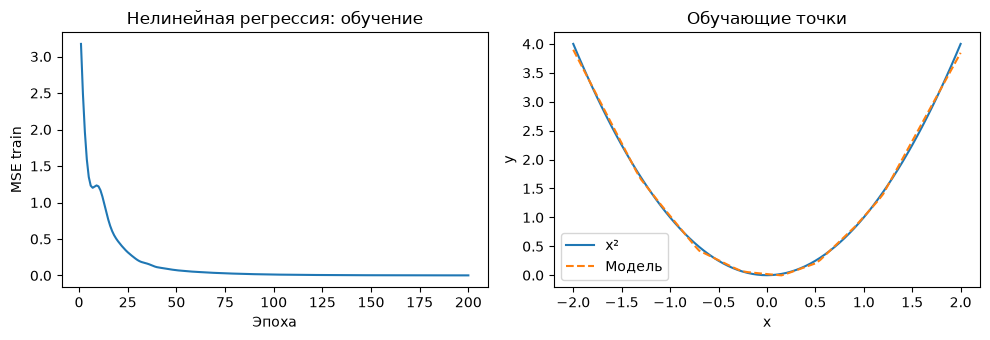

In [7]:
torch.manual_seed(7)
x_curve = torch.linspace(-2, 2, 81).reshape(-1, 1)
y_curve = x_curve ** 2
curve_model = nn.Sequential(nn.Linear(1, 16), nn.ReLU(), nn.Linear(16, 1))
loss_function = nn.MSELoss()
optimizer = optim.Adam(curve_model.parameters(), lr=0.03)
curve_losses = []

for epoch in range(200):
    optimizer.zero_grad()
    prediction = curve_model(x_curve)
    loss = loss_function(prediction, y_curve)
    loss.backward()
    optimizer.step()
    curve_losses.append(loss.item())

with torch.no_grad():
    curve_prediction = curve_model(x_curve)
print("MSE после обучения", loss_function(curve_prediction, y_curve).item())
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
axes[0].plot(range(1,201),curve_losses)
axes[0].set(xlabel="Эпоха",ylabel="MSE train",title="Нелинейная регрессия: обучение")
axes[1].plot(x_curve.numpy(),y_curve.numpy(),label="x²")
axes[1].plot(x_curve.numpy(),curve_prediction.numpy(),"--",label="Модель")
axes[1].set(xlabel="x",ylabel="y",title="Обучающие точки");axes[1].legend()
plt.tight_layout();savefig("01_tensor_regression.png")

In [8]:
logits = torch.tensor([[2., 1., 0.], [0., 1., 2.]])
labels = torch.tensor([0, 2], dtype=torch.long)
probabilities = torch.softmax(logits, dim=1)
manual_loss = -torch.log(probabilities[torch.arange(2), labels]).mean()
loss = nn.CrossEntropyLoss()(logits, labels)

print("Вероятности\n", probabilities)
print("Ответы", logits.argmax(dim=1))
print("Вручную", manual_loss.item(), "CrossEntropyLoss", loss.item())
assert torch.allclose(manual_loss,loss)

Вероятности
 tensor([[0.665, 0.245, 0.090],
        [0.090, 0.245, 0.665]])
Ответы tensor([0, 2])
Вручную 0.40760597586631775 CrossEntropyLoss 0.40760594606399536


**Вывод:** CrossEntropyLoss получает логиты; Softmax отдельно перед ней не нужен. В примере проверено совпадение с ручной кросс-энтропией.

## 3. Dataset, DataLoader и общий цикл обучения

In [9]:
from torch.utils.data import Dataset, DataLoader, TensorDataset, random_split

class PairsDataset(Dataset):
    def __init__(self, features, targets):
        self.features = features
        self.targets = targets

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, index):
        return self.features[index], self.targets[index]

features = torch.arange(12, dtype=torch.float32).reshape(6, 2)
targets = torch.tensor([0, 1, 0, 1, 0, 1])
pairs = PairsDataset(features, targets)
print("Всего объектов", len(pairs))
print("Объект с индексом 2", pairs[2])

manual_features = torch.stack([pairs[0][0], pairs[1][0]])
manual_targets = torch.stack([pairs[0][1], pairs[1][1]])
print("Ручной пакет\n", manual_features, manual_targets)

loader = DataLoader(pairs, batch_size=2, shuffle=False, num_workers=0)
for batch_number, (x_batch, y_batch) in enumerate(loader):
    print("Пакет", batch_number, "формы", x_batch.shape, y_batch.shape)
    print(x_batch, y_batch)

print("len(Dataset)", len(pairs), "len(DataLoader)", len(loader))

tensor_pairs = TensorDataset(features, targets)
print("Тот же объект из TensorDataset", tensor_pairs[2])

shuffled_loader = DataLoader(
    pairs, batch_size=4, shuffle=True, num_workers=0,
    generator=torch.Generator().manual_seed(42)
)
for x_batch, y_batch in shuffled_loader:
    print("Признаки", x_batch.tolist(), "метки", y_batch.tolist())

Всего объектов 6
Объект с индексом 2 (tensor([4., 5.]), tensor(0))
Ручной пакет
 tensor([[0., 1.],
        [2., 3.]]) tensor([0, 1])
Пакет 0 формы torch.Size([2, 2]) torch.Size([2])
tensor([[0., 1.],
        [2., 3.]]) tensor([0, 1])
Пакет 1 формы torch.Size([2, 2]) torch.Size([2])
tensor([[4., 5.],
        [6., 7.]]) tensor([0, 1])
Пакет 2 формы torch.Size([2, 2]) torch.Size([2])
tensor([[ 8.,  9.],
        [10., 11.]]) tensor([0, 1])
len(Dataset) 6 len(DataLoader) 3
Тот же объект из TensorDataset (tensor([4., 5.]), tensor(0))
Признаки [[8.0, 9.0], [10.0, 11.0], [0.0, 1.0], [2.0, 3.0]] метки [0, 1, 0, 1]
Признаки [[4.0, 5.0], [6.0, 7.0]] метки [0, 1]


**Вывод:** Dataset возвращает один объект с меткой; DataLoader собирает и перемешивает пакеты. Для valid/test перемешивание выключено, num_workers=0 подходит для Windows.

In [10]:
def synchronize():
    if device.type=="cuda":torch.cuda.synchronize()
    elif device.type=="mps":torch.mps.synchronize()

@torch.no_grad()
def predict(model,loader):
    model.eval()
    answers,predictions,probabilities=[],[],[]
    for images,labels in loader:
        logits=model(images.to(device))
        answers.append(labels.cpu())
        predictions.append(logits.argmax(1).cpu())
        probabilities.append(logits.softmax(1).cpu())
    return (torch.cat(answers).numpy(),torch.cat(predictions).numpy(),
            torch.cat(probabilities).numpy())

def fit(model,train_data,valid_loader,name):
    # Один порядок train-пакетов для сравниваемых моделей.
    loader=DataLoader(train_data,batch_size=128,shuffle=True,num_workers=0,
        generator=torch.Generator().manual_seed(SEED))
    optimizer=optim.Adam(model.parameters(),lr=.001)
    criterion=nn.CrossEntropyLoss()
    history=[]
    for epoch in range(1,6):
        model.train()
        synchronize();started=perf_counter();loss_sum=0.
        for images,labels in loader:
            images,labels=images.to(device),labels.to(device)
            optimizer.zero_grad()
            logits=model(images)
            loss=criterion(logits,labels)
            loss.backward()
            optimizer.step()
            loss_sum+=loss.item()*len(labels)
        synchronize();train_seconds=perf_counter()-started
        answers,predictions,_=predict(model,valid_loader)
        row=dict(epoch=epoch,train_loss=loss_sum/len(train_data),
                 valid_accuracy=float(accuracy_score(answers,predictions)),
                 train_seconds=train_seconds)
        history.append(row);print(name,row,flush=True)
    frame=pd.DataFrame(history)
    frame.to_csv(OUT/f"{name}_history.csv",index=False)
    return frame

def assess(model,loader,name,class_names):
    # eval и no_grad не должны изменять веса или буферы BatchNorm.
    snapshot={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
    answers,predictions,probability=predict(model,loader)
    assert all(torch.equal(snapshot[k],v.detach().cpu()) for k,v in model.state_dict().items())
    metrics=dict(accuracy=float(accuracy_score(answers,predictions)),
        macro_f1=float(f1_score(answers,predictions,labels=range(len(class_names)),
            average="macro",zero_division=0)),test_size=len(answers),parameters=params(model))
    report=pd.DataFrame(classification_report(answers,predictions,labels=range(len(class_names)),
        target_names=class_names,output_dict=True,zero_division=0)).T
    report.to_csv(OUT/f"{name}_by_class.csv")
    pd.DataFrame(dict(label=answers,prediction=predictions,confidence=probability.max(1))).to_csv(OUT/f"{name}_predictions.csv",index=False)
    (OUT/f"{name}_metrics.json").write_text(json.dumps(metrics,indent=2),encoding="utf-8")
    torch.save({k:v.detach().cpu() for k,v in model.state_dict().items()},OUT/f"{name}_weights.pt")
    print(name,metrics)
    return answers,predictions,probability,metrics

def confusion_plot(answers,predictions,names,title,filename):
    fig,ax=plt.subplots(figsize=(6,5))
    ConfusionMatrixDisplay.from_predictions(answers,predictions,
        labels=range(len(names)),display_labels=names,ax=ax,colorbar=False)
    ax.set(xlabel="Предсказанный класс",ylabel="Истинный класс",title=title)
    ax.tick_params(axis="x",rotation=30)
    plt.tight_layout();savefig(filename)

## 4. MNIST: линейная классификация цифр

Из исходного train выделяем 10 000 объектов train и 2 000 valid по seed=42. Официальные 10 000 test используются только после пяти эпох.

Torchvision

 0.29.2+cpu
Это Dataset True
Объектов 60000
Изображение torch.Size([1, 28, 28]) torch.float32
Диапазон 0.0 1.0 Метка 5


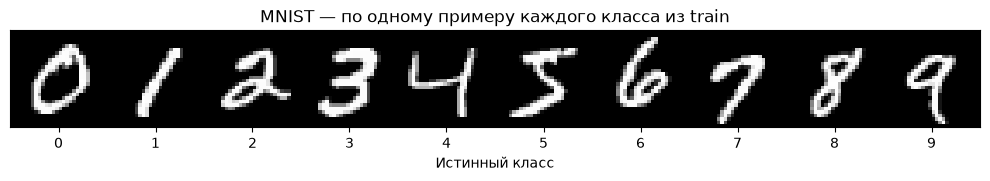

In [11]:
import torchvision
from torchvision import datasets, transforms

mnist_source = datasets.MNIST(
    root=str(DATA), train=True, download=True,
    transform=transforms.ToTensor()
)
image, label = mnist_source[0]
manual_image = mnist_source.data[0].unsqueeze(0).float() / 255

print("Torchvision", torchvision.__version__)
print("Это Dataset", isinstance(mnist_source, Dataset))
print("Объектов", len(mnist_source))
print("Изображение", image.shape, image.dtype)
print("Диапазон", image.min().item(), image.max().item(), "Метка", label)

examples = []
for digit in range(10):
    index = torch.where(mnist_source.targets == digit)[0][0].item()
    examples.append(mnist_source[index][0])

strip = torch.cat(examples, dim=2).squeeze(0)
plt.figure(figsize=(10, 2.8))
# Для показа оттенков серого используем одинаковые значения R, G и B.
plt.imshow(np.repeat(strip.numpy()[:, :, None], 3, axis=2), interpolation="nearest")
plt.xticks(np.arange(10) * 28 + 13.5, range(10))
plt.yticks([])
plt.xlabel("Истинный класс")
plt.title("MNIST — по одному примеру каждого класса из train")
plt.tight_layout()
savefig("02_mnist_examples.png")

In [12]:
mnist_train, mnist_valid, mnist_unused = random_split(
    mnist_source, [10000, 2000, len(mnist_source) - 12000],
    generator=torch.Generator().manual_seed(42)
)
mnist_train_loader = DataLoader(
    mnist_train, batch_size=128, shuffle=True, num_workers=0,
    generator=torch.Generator().manual_seed(42)
)
mnist_valid_loader = DataLoader(
    mnist_valid, batch_size=256, shuffle=False, num_workers=0
)
images, labels = next(iter(mnist_train_loader))
print("Train", len(mnist_train), "Valid", len(mnist_valid))
print("Пакет изображений", images.shape, images.dtype)
print("Пакет меток", labels.shape, labels.dtype)

torch.manual_seed(42)
mnist_model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 10)
).to(device)

print(mnist_model)
print("Параметров", sum(p.numel() for p in mnist_model.parameters()))
with torch.no_grad():
    logits = mnist_model(images.to(device))
print("Форма логитов", logits.shape)
print("Первые ответы до обучения", logits.argmax(dim=1)[:10].cpu())
assert not set(mnist_train.indices)&set(mnist_valid.indices)
assert params(mnist_model)==7850
np.savez_compressed(OUT/"mnist_split.npz",train=mnist_train.indices,valid=mnist_valid.indices)

Train 10000 Valid 2000
Пакет изображений torch.Size([128, 1, 28, 28]) torch.float32
Пакет меток torch.Size([128]) torch.int64
Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=10, bias=True)
)
Параметров 7850
Форма логитов torch.Size([128, 10])
Первые ответы до обучения tensor([3, 9, 8, 6, 6, 9, 3, 6, 3, 9])


mnist {'epoch': 1, 'train_loss': 1.356248150062561, 'valid_accuracy': 0.839, 'train_seconds': 1.4716484000000492}


mnist {'epoch': 2, 'train_loss': 0.7047186183452606, 'valid_accuracy': 0.8675, 'train_seconds': 1.30014650000021}


mnist {'epoch': 3, 'train_loss': 0.544949049282074, 'valid_accuracy': 0.881, 'train_seconds': 1.199622300000101}


mnist {'epoch': 4, 'train_loss': 0.47068918414115907, 'valid_accuracy': 0.8915, 'train_seconds': 1.1928210999999465}


mnist {'epoch': 5, 'train_loss': 0.4253472828388214, 'valid_accuracy': 0.894, 'train_seconds': 1.189204399999653}


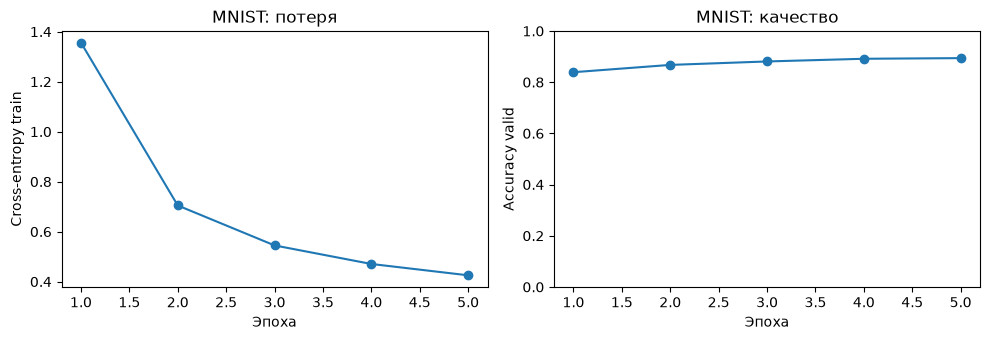

mnist {'accuracy': 0.8987, 'macro_f1': 0.8975230504735325, 'test_size': 10000, 'parameters': 7850}


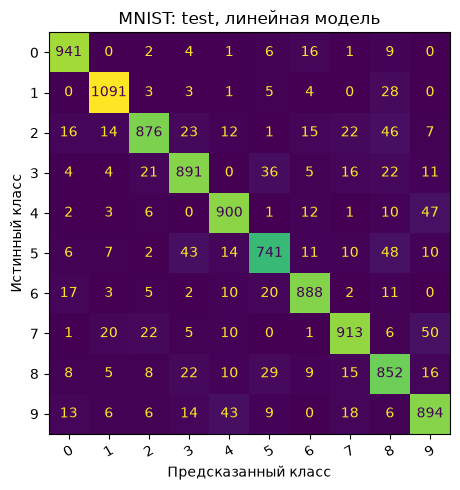

In [13]:
mnist_history=fit(mnist_model,mnist_train,mnist_valid_loader,"mnist")
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
axes[0].plot(mnist_history.epoch,mnist_history.train_loss,"o-")
axes[0].set(xlabel="Эпоха",ylabel="Cross-entropy train",title="MNIST: потеря")
axes[1].plot(mnist_history.epoch,mnist_history.valid_accuracy,"o-")
axes[1].set(xlabel="Эпоха",ylabel="Accuracy valid",ylim=(0,1),title="MNIST: качество")
plt.tight_layout();savefig("03_mnist_history.png")
mnist_test=datasets.MNIST(root=str(DATA),train=False,download=True,transform=transforms.ToTensor())
mnist_test_loader=DataLoader(mnist_test,batch_size=256,shuffle=False,num_workers=0)
mnist_answers,mnist_predictions,mnist_probability,mnist_metrics=assess(
    mnist_model,mnist_test_loader,"mnist",[str(i) for i in range(10)])
confusion_plot(mnist_answers,mnist_predictions,[str(i) for i in range(10)],
    "MNIST: test, линейная модель","04_mnist_confusion.png")

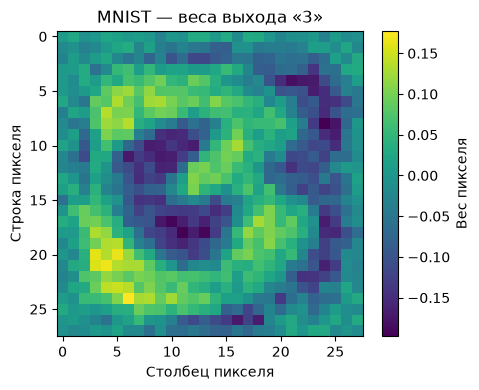

In [14]:
weight_image = mnist_model[1].weight[3].detach().cpu().reshape(28, 28)
plt.figure(figsize=(5, 4))
plt.imshow(weight_image, interpolation="nearest")
plt.colorbar(label="Вес пикселя")
plt.xlabel("Столбец пикселя")
plt.ylabel("Строка пикселя")
plt.title("MNIST — веса выхода «3»")
plt.tight_layout()
savefig("05_mnist_weights.png")

**Вывод:** одна строка весов показывает вклад пикселей в логит цифры 3. Это не вероятности пикселей; окончательный класс определяется сравнением всех десяти логитов.

## 5. Свёртка, pooling и BatchNorm

Свёртка PyTorch использует ядро без переворота. Вручную сверяем карту откликов, шаг, padding и суммирование входных каналов.

In [15]:
map_2d = torch.tensor([[1., 2., 3., 4.],
                       [5., 6., 7., 8.],
                       [9., 10., 11., 12.],
                       [13., 14., 15., 16.]])
map_4d = map_2d.unsqueeze(0).unsqueeze(0)
max_pool = nn.MaxPool2d(kernel_size=2, stride=2)
avg_pool = nn.AvgPool2d(kernel_size=2, stride=2)

print("Вход NCHW", map_4d.shape)
print("Первый блок\n", map_2d[:2, :2])
print("Его максимум", map_2d[:2, :2].max().item())
print("Его среднее", map_2d[:2, :2].mean().item())
print("MaxPool\n", max_pool(map_4d)[0, 0])
print("AvgPool\n", avg_pool(map_4d)[0, 0])

map_2d = torch.tensor([[0., 0., 1., 1., 1.],
                       [0., 0., 1., 1., 1.],
                       [0., 0., 1., 1., 1.],
                       [0., 0., 1., 1., 1.],
                       [0., 0., 1., 1., 1.]])
kernel = torch.tensor([[-1., 0., 1.],
                       [-1., 0., 1.],
                       [-1., 0., 1.]])
patch = map_2d[:3, :3]
print("Первое окно\n", patch)
print("Произведения\n", patch * kernel)
print("Первый отклик", (patch * kernel).sum().item())

manual_map = torch.zeros(3, 3)
for row in range(3):
    for column in range(3):
        patch = map_2d[row:row + 3, column:column + 3]
        manual_map[row, column] = (patch * kernel).sum()
print("Вся карта вручную\n", manual_map)

conv = nn.Conv2d(1, 1, kernel_size=3, bias=False)
with torch.no_grad():
    conv.weight[0, 0].copy_(kernel)
    output = conv(map_2d[None, None])

print("Форма весов", conv.weight.shape)
print("Форма выхода", output.shape)
print("Результат Conv2d\n", output[0, 0])
assert torch.allclose(output[0, 0], manual_map)

rows = []
for padding, stride in [(0, 1), (1, 1), (1, 2)]:
    conv = nn.Conv2d(1, 1, 3, padding=padding, stride=stride, bias=False)
    with torch.no_grad():
        conv.weight[0, 0].copy_(kernel)
        result = conv(map_2d[None, None])
    rows.append([padding, stride, tuple(result.shape),
                 sum(p.numel() for p in conv.parameters())])
pd.DataFrame(rows, columns=["padding", "stride", "Форма выхода", "Параметров"])
assert torch.allclose(output[0,0],manual_map)

Вход NCHW torch.Size([1, 1, 4, 4])
Первый блок
 tensor([[1., 2.],
        [5., 6.]])
Его максимум 6.0
Его среднее 3.5
MaxPool
 tensor([[ 6.,  8.],
        [14., 16.]])
AvgPool
 tensor([[ 3.500,  5.500],
        [11.500, 13.500]])
Первое окно
 tensor([[0., 0., 1.],
        [0., 0., 1.],
        [0., 0., 1.]])
Произведения
 tensor([[-0., 0., 1.],
        [-0., 0., 1.],
        [-0., 0., 1.]])
Первый отклик 3.0
Вся карта вручную
 tensor([[3., 3., 0.],
        [3., 3., 0.],
        [3., 3., 0.]])
Форма весов torch.Size([1, 1, 3, 3])
Форма выхода torch.Size([1, 1, 3, 3])
Результат Conv2d
 tensor([[3., 3., 0.],
        [3., 3., 0.],
        [3., 3., 0.]])


In [16]:
two_channels = torch.stack([map_2d, 2 * map_2d]).unsqueeze(0)
conv = nn.Conv2d(2, 2, kernel_size=3, bias=False)
with torch.no_grad():
    conv.weight[0].fill_(1)
    conv.weight[1].fill_(-1)
    result = conv(two_channels)

manual_first = two_channels[0, :, :3, :3].sum()
print("Вход", two_channels.shape, "Веса", conv.weight.shape)
print("Выход", result.shape)
print("Первая позиция вручную", manual_first.item())
print("Первая выходная карта\n", result[0, 0])
print("Вторая выходная карта\n", result[0, 1])

maps = torch.arange(1, 17, dtype=torch.float32).reshape(2, 2, 2, 2)
bn = nn.BatchNorm2d(2, eps=1e-5, momentum=0.1)
bn.train()

mean = maps.mean(dim=(0, 2, 3), keepdim=True)
variance = maps.var(dim=(0, 2, 3), unbiased=False, keepdim=True)
manual_normalized = (maps - mean) / torch.sqrt(variance + 1e-5)
with torch.no_grad():
    normalized = bn(maps)

print("Среднее каждого канала до", mean.flatten())
print("Дисперсия каждого канала до", variance.flatten())
print("Средние после", normalized.mean(dim=(0, 2, 3)))
print("Дисперсии после", normalized.var(dim=(0, 2, 3), unbiased=False))
print("Форма", normalized.shape, "Параметров", sum(p.numel() for p in bn.parameters()))

print("Накопленное среднее", bn.running_mean)
print("Накопленная дисперсия", bn.running_var)
bn.eval()
with torch.no_grad():
    evaluated = bn(maps)
    manual_eval = (maps - bn.running_mean[None, :, None, None])
    manual_eval = manual_eval / torch.sqrt(bn.running_var[None, :, None, None] + bn.eps)
    manual_eval = manual_eval * bn.weight[None, :, None, None] + bn.bias[None, :, None, None]
print("Средние выхода eval", evaluated.mean(dim=(0, 2, 3)))
print("Число обработанных обучающих пакетов", bn.num_batches_tracked.item())
assert torch.allclose(normalized,manual_normalized,atol=1e-5)
assert torch.allclose(evaluated,manual_eval,atol=1e-5)

Вход torch.Size([1, 2, 5, 5]) Веса torch.Size([2, 2, 3, 3])
Выход torch.Size([1, 2, 3, 3])
Первая позиция вручную 9.0
Первая выходная карта
 tensor([[ 9., 18., 27.],
        [ 9., 18., 27.],
        [ 9., 18., 27.]])
Вторая выходная карта
 tensor([[ -9., -18., -27.],
        [ -9., -18., -27.],
        [ -9., -18., -27.]])
Среднее каждого канала до tensor([ 6.500, 10.500])
Дисперсия каждого канала до tensor([17.250, 17.250])
Средние после tensor([-0.000,  0.000])
Дисперсии после tensor([1.000, 1.000])
Форма torch.Size([2, 2, 2, 2]) Параметров 4
Накопленное среднее tensor([0.650, 1.050])
Накопленная дисперсия tensor([2.871, 2.871])
Средние выхода eval tensor([3.452, 5.577])
Число обработанных обучающих пакетов 1


**Вывод:** pooling не обучает веса. Conv2d суммирует отклики всех входных каналов; одно ядро повторяется в разных позициях. BatchNorm2d в train считает статистики по N,H,W отдельно для каждого C, в eval использует накопленные оценки.

## 6. BloodMNIST: линейная модель против CNN

Одинаковые данные и нормировка для обеих моделей: 600 train-изображений каждого из восьми классов, всего 4 800. Официальные valid/test оставляем целиком; архитектуры, Adam и пять эпох заданы заранее.

Train (11959, 28, 28, 3) (11959,)
Valid (1712, 28, 28, 3) (1712,)
Test (3421, 28, 28, 3) (3421,)


,Код,Класс,Изображений в исходном train
0,0,Базофил,852
1,1,Эозинофил,2181
2,2,Эритробласт,1085
3,3,Незрелые гранулоциты,2026
4,4,Лимфоцит,849
5,5,Моноцит,993
6,6,Нейтрофил,2330
7,7,Тромбоцит,1643


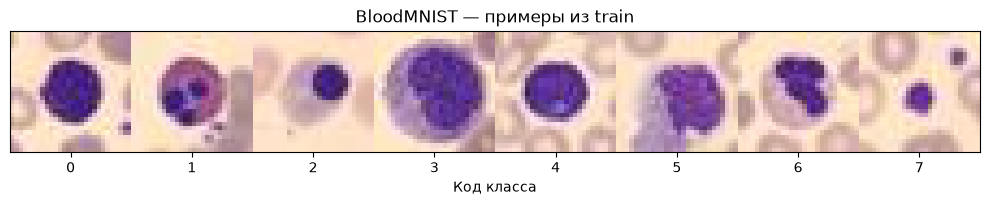

In [17]:
from pathlib import Path
from PIL import Image
from torchvision import transforms
from torchvision.datasets.utils import download_url

blood_root = DATA
blood_root.mkdir(exist_ok=True)
download_url(
    "https://zenodo.org/records/10519652/files/bloodmnist.npz?download=1",
    root=str(blood_root), filename="bloodmnist.npz",
    md5="7053d0359d879ad8a5505303e11de1dc"
)
with np.load(blood_root / "bloodmnist.npz") as data:
    blood_train_images = data["train_images"]
    blood_train_labels = data["train_labels"].reshape(-1)
    blood_valid_images = data["val_images"]
    blood_valid_labels = data["val_labels"].reshape(-1)
    blood_test_images = data["test_images"]
    blood_test_labels = data["test_labels"].reshape(-1)

print("Train", blood_train_images.shape, blood_train_labels.shape)
print("Valid", blood_valid_images.shape, blood_valid_labels.shape)
print("Test", blood_test_images.shape, blood_test_labels.shape)

blood_names = ["Базофил", "Эозинофил", "Эритробласт",
               "Незрелые гранулоциты", "Лимфоцит", "Моноцит",
               "Нейтрофил", "Тромбоцит"]
display(pd.DataFrame({"Код": range(8), "Класс": blood_names,
    "Изображений в исходном train": np.bincount(blood_train_labels, minlength=8)}))
example_indices = [np.flatnonzero(blood_train_labels == k)[0] for k in range(8)]
strip = np.concatenate(blood_train_images[example_indices], axis=1)
plt.figure(figsize=(10, 3))
plt.imshow(strip)
plt.xticks(np.arange(8) * 28 + 13.5, range(8))
plt.yticks([])
plt.xlabel("Код класса")
plt.title("BloodMNIST — примеры из train")
plt.tight_layout()
savefig("06_blood_examples.png")

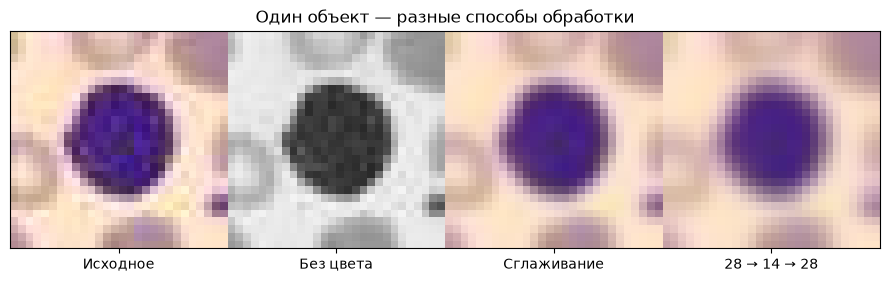

In [18]:
original = Image.fromarray(blood_train_images[example_indices[0]])
gray = transforms.Grayscale(num_output_channels=3)(original)
blurred = transforms.GaussianBlur(kernel_size=3, sigma=1.0)(original)
small = transforms.Resize((14, 14), antialias=True)(original)
resized_back = transforms.Resize((28, 28), antialias=True)(small)
strip = np.concatenate([np.array(im) for im in
                        [original, gray, blurred, resized_back]], axis=1)
plt.figure(figsize=(9, 3))
plt.imshow(strip)
plt.xticks(np.arange(4) * 28 + 13.5,
           ["Исходное", "Без цвета", "Сглаживание", "28 → 14 → 28"])
plt.yticks([])
plt.title("Один объект — разные способы обработки")
plt.tight_layout()
savefig("07_blood_transforms.png")

**Вывод:** перевод в серый теряет цвет, размытие — мелкие границы, уменьшение с обратным увеличением не восстанавливает детали. Для обучения оставляем RGB и нормировку каналов в диапазон примерно −1…1.

Объект torch.Size([3, 28, 28]) torch.float32 Метка 0
Train 4800 Valid 1712 Test 3421
Линейная модель 18824
CNN 7696


,Номер,Слой,Форма выхода,Параметров
0,0,Conv2d,"(1, 8, 28, 28)",216
1,1,BatchNorm2d,"(1, 8, 28, 28)",16
2,2,ReLU,"(1, 8, 28, 28)",0
3,3,MaxPool2d,"(1, 8, 14, 14)",0
4,4,Conv2d,"(1, 16, 14, 14)",1152
5,5,BatchNorm2d,"(1, 16, 14, 14)",32
6,6,ReLU,"(1, 16, 14, 14)",0
7,7,MaxPool2d,"(1, 16, 7, 7)",0
8,8,Flatten,"(1, 784)",0
9,9,Linear,"(1, 8)",6280


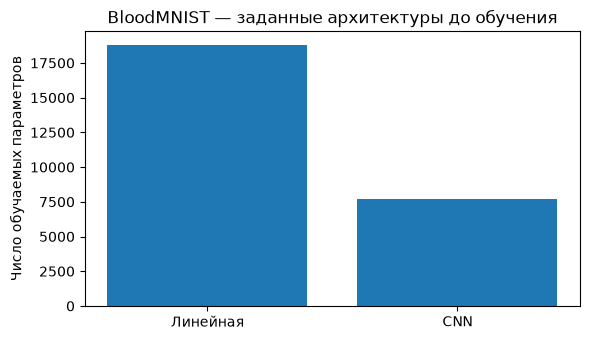

In [19]:
class BloodDataset(Dataset):
    def __init__(self, images, labels, transform):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        image = Image.fromarray(self.images[index])
        image = self.transform(image)
        label = int(self.labels[index])
        return image, label

blood_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
])

rng = np.random.default_rng(42)
train_indices = []
for label in range(8):
    candidates = np.flatnonzero(blood_train_labels == label)
    train_indices.extend(rng.choice(candidates, size=600, replace=False))
train_indices = np.array(train_indices)

blood_train = BloodDataset(blood_train_images[train_indices],
                          blood_train_labels[train_indices], blood_transform)
blood_valid = BloodDataset(blood_valid_images, blood_valid_labels, blood_transform)
blood_test = BloodDataset(blood_test_images, blood_test_labels, blood_transform)
blood_valid_loader = DataLoader(blood_valid, batch_size=256, shuffle=False, num_workers=0)
blood_test_loader = DataLoader(blood_test, batch_size=256, shuffle=False, num_workers=0)

image, label = blood_train[0]
print("Объект", image.shape, image.dtype, "Метка", label)
print("Train", len(blood_train), "Valid", len(blood_valid), "Test", len(blood_test))

torch.manual_seed(42)
blood_linear = nn.Sequential(
    nn.Flatten(),
    nn.Linear(3 * 28 * 28, 8)
).to(device)

torch.manual_seed(42)
blood_cnn = nn.Sequential(
    nn.Conv2d(3, 8, kernel_size=3, padding=1, bias=False),
    nn.BatchNorm2d(8),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(8, 16, kernel_size=3, padding=1, bias=False),
    nn.BatchNorm2d(16),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(16 * 7 * 7, 8)
).to(device)

print("Линейная модель", sum(p.numel() for p in blood_linear.parameters()))
print("CNN", sum(p.numel() for p in blood_cnn.parameters()))

blood_cnn.eval()
current = torch.zeros(1, 3, 28, 28, device=device)
rows = []
with torch.no_grad():
    for index, layer in enumerate(blood_cnn):
        current = layer(current)
        rows.append([index, type(layer).__name__, tuple(current.shape),
                     sum(p.numel() for p in layer.parameters())])
display(pd.DataFrame(rows, columns=["Номер", "Слой", "Форма выхода", "Параметров"]))

parameter_counts = [sum(p.numel() for p in blood_linear.parameters()),
                    sum(p.numel() for p in blood_cnn.parameters())]
plt.figure(figsize=(6, 3.5))
plt.bar(["Линейная", "CNN"], parameter_counts)
plt.ylabel("Число обучаемых параметров")
plt.title("BloodMNIST — заданные архитектуры до обучения")
plt.tight_layout()
savefig("08_blood_parameters.png")
assert len(blood_train)==4800
assert params(blood_linear)==18824 and params(blood_cnn)==7696
np.savez_compressed(OUT/"blood_train_indices.npz",indices=train_indices)

blood_linear {'epoch': 1, 'train_loss': 1.3429274241129556, 'valid_accuracy': 0.6886682242990654, 'train_seconds': 1.1106391999996958}


blood_linear {'epoch': 2, 'train_loss': 0.9567575430870057, 'valid_accuracy': 0.7225467289719626, 'train_seconds': 1.0498969000000216}


blood_linear {'epoch': 3, 'train_loss': 0.8661207755406698, 'valid_accuracy': 0.7213785046728972, 'train_seconds': 1.063823300000422}


blood_linear {'epoch': 4, 'train_loss': 0.8178169226646423, 'valid_accuracy': 0.7424065420560748, 'train_seconds': 1.0664286999999604}


blood_linear {'epoch': 5, 'train_loss': 0.776993924776713, 'valid_accuracy': 0.7558411214953271, 'train_seconds': 1.2075262999996994}


blood_cnn {'epoch': 1, 'train_loss': 1.3446198805173237, 'valid_accuracy': 0.4608644859813084, 'train_seconds': 2.027528899999652}


blood_cnn {'epoch': 2, 'train_loss': 0.7650938947995504, 'valid_accuracy': 0.7686915887850467, 'train_seconds': 2.015783299999839}


blood_cnn {'epoch': 3, 'train_loss': 0.6076538594563802, 'valid_accuracy': 0.8288551401869159, 'train_seconds': 2.0872386000000915}


blood_cnn {'epoch': 4, 'train_loss': 0.5100155027707418, 'valid_accuracy': 0.8481308411214953, 'train_seconds': 2.2165878999999222}


blood_cnn {'epoch': 5, 'train_loss': 0.44359357754389445, 'valid_accuracy': 0.856892523364486, 'train_seconds': 2.179673300000104}


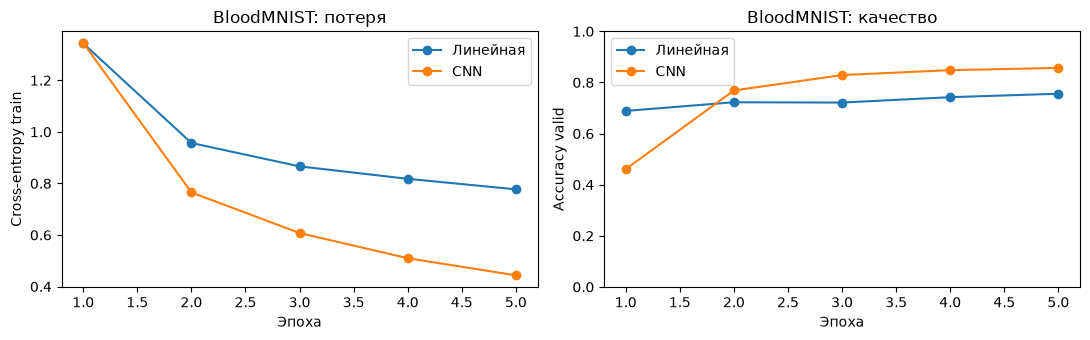

In [20]:
linear_history=fit(blood_linear,blood_train,blood_valid_loader,"blood_linear")
cnn_history=fit(blood_cnn,blood_train,blood_valid_loader,"blood_cnn")
fig,axes=plt.subplots(1,2,figsize=(11,3.5))
for label,history in [("Линейная",linear_history),("CNN",cnn_history)]:
    axes[0].plot(history.epoch,history.train_loss,"o-",label=label)
    axes[1].plot(history.epoch,history.valid_accuracy,"o-",label=label)
axes[0].set(xlabel="Эпоха",ylabel="Cross-entropy train",title="BloodMNIST: потеря")
axes[1].set(xlabel="Эпоха",ylabel="Accuracy valid",ylim=(0,1),title="BloodMNIST: качество")
for ax in axes:ax.legend()
plt.tight_layout();savefig("09_blood_history.png")

Карты первого блока torch.Size([1, 8, 28, 28])
Вектор признаков torch.Size([1, 784])
Логиты torch.Size([1, 8])


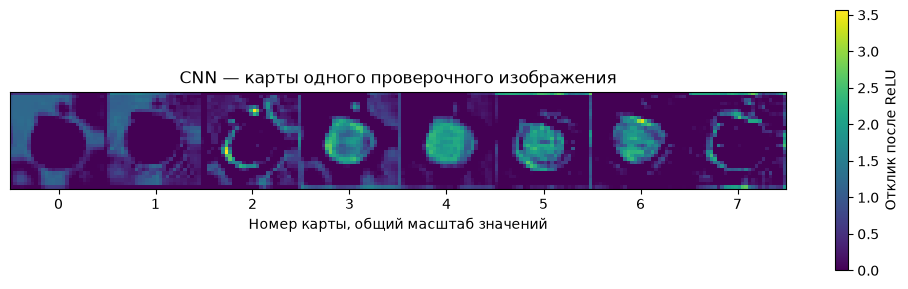

In [21]:
blood_cnn.eval()
image, label = blood_valid[0]
with torch.no_grad():
    x = image.unsqueeze(0).to(device)
    first_maps = blood_cnn[:3](x).cpu()
    feature_vector = blood_cnn[:-1](x)
    logits_from_vector = blood_cnn[-1](feature_vector)
    logits_direct = blood_cnn(x)

print("Карты первого блока", first_maps.shape)
print("Вектор признаков", feature_vector.shape)
print("Логиты", logits_from_vector.shape)

strip = torch.cat(list(first_maps[0]), dim=1)
plt.figure(figsize=(10, 3))
plt.imshow(strip, interpolation="nearest")
plt.xticks(np.arange(8) * 28 + 13.5, range(8))
plt.yticks([])
plt.xlabel("Номер карты, общий масштаб значений")
plt.title("CNN — карты одного проверочного изображения")
plt.colorbar(label="Отклик после ReLU")
plt.tight_layout()
savefig("10_blood_feature_maps.png")
assert torch.allclose(logits_from_vector,logits_direct)

**Вывод:** первый блок CNN создаёт восемь карт; перед последним Linear изображение превращается в вектор из 784 признаков. Прямой проход через выделенный вектор совпал с полным проходом сети.

Устройство cpu Потоков CPU 2


,Модель,"Пакет 64, мс"
0,Линейная,0.172
1,CNN,6.713


blood_linear {'accuracy': 0.735749780765858, 'macro_f1': 0.7101353552317717, 'test_size': 3421, 'parameters': 18824}


blood_cnn {'accuracy': 0.8468284127448115, 'macro_f1': 0.828712318678928, 'test_size': 3421, 'parameters': 7696}


,Модель,Accuracy test,Macro-F1 test,Параметров,"Обучение 5 эпох, с","Пакет 64, мс"
0,Линейная,0.7357,0.7101,18824,5.4983,0.1718
1,CNN,0.8468,0.8287,7696,10.5268,6.7133


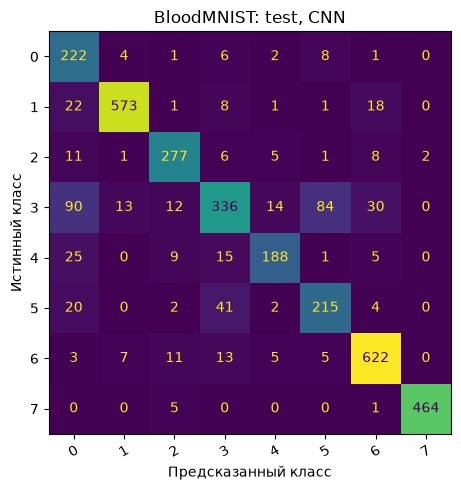

In [22]:
speed_loader = DataLoader(blood_valid, batch_size=64, shuffle=False, num_workers=0)
speed_images, _ = next(iter(speed_loader))
speed_images = speed_images.to(device)
speed_rows = []

for name, model in [("Линейная", blood_linear), ("CNN", blood_cnn)]:
    model.eval()
    measurements = []
    with torch.no_grad():
        for _ in range(10):
            model(speed_images)
        for repeat in range(3):
            if device.type == "cuda":
                torch.cuda.synchronize()
            elif device.type == "mps":
                torch.mps.synchronize()
            started = perf_counter()
            for _ in range(30):
                model(speed_images)
            if device.type == "cuda":
                torch.cuda.synchronize()
            elif device.type == "mps":
                torch.mps.synchronize()
            measurements.append((perf_counter() - started) / 30)
    speed_rows.append([name, np.median(measurements) * 1000])

speed_table = pd.DataFrame(speed_rows, columns=["Модель", "Пакет 64, мс"])
print("Устройство", device, "Потоков CPU", torch.get_num_threads())
if device.type == "cuda":
    print("GPU", torch.cuda.get_device_name())
display(speed_table.round(3))
blood_predictions={};blood_rows=[]
for key,label,model,history in [
    ("blood_linear","Линейная",blood_linear,linear_history),
    ("blood_cnn","CNN",blood_cnn,cnn_history)]:
    truth,predicted,probability,metrics=assess(model,blood_test_loader,key,blood_names)
    blood_predictions[label]=predicted
    blood_rows.append({"Модель":label,"Accuracy test":metrics["accuracy"],
        "Macro-F1 test":metrics["macro_f1"],"Параметров":metrics["parameters"],
        "Обучение 5 эпох, с":float(history.train_seconds.sum())})
comparison=pd.DataFrame(blood_rows).merge(speed_table,on="Модель")
comparison.to_csv(OUT/"bloodmnist_comparison.csv",index=False)
display(comparison.round(4))
confusion_plot(blood_test_labels,blood_predictions["CNN"],[str(i) for i in range(8)],
    "BloodMNIST: test, CNN","11_blood_confusion.png")

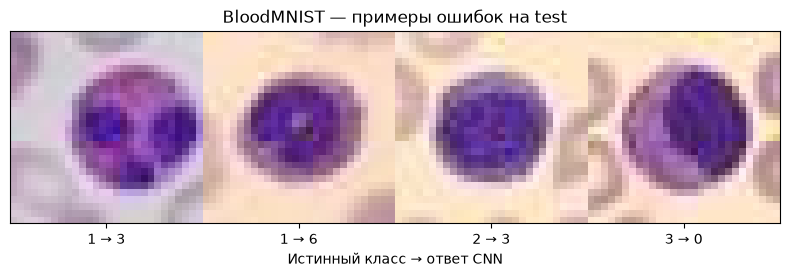

In [23]:
error_indices = np.flatnonzero(blood_predictions["CNN"] != blood_test_labels)[:4]
if len(error_indices) > 0:
    strip = np.concatenate(blood_test_images[error_indices], axis=1)
    captions = [f"{blood_test_labels[i]} → {blood_predictions['CNN'][i]}"
                for i in error_indices]
    plt.figure(figsize=(8, 3))
    plt.imshow(strip)
    plt.xticks(np.arange(len(error_indices)) * 28 + 13.5, captions)
    plt.yticks([])
    plt.xlabel("Истинный класс → ответ CNN")
    plt.title("BloodMNIST — примеры ошибок на test")
    plt.tight_layout()
    savefig("12_blood_errors.png")
else:
    print("На этой тестовой части ошибок нет.")

**Вывод:** сравниваем качество, число параметров и время отдельно. Малое число весов CNN не гарантирует быстрого применения: свёртки создают и обрабатывают карты признаков. Время относится к этому устройству, пакету 64 и исключает чтение/перенос данных.

## 7. Самостоятельная часть: CIFAR-10, вариант №1

Правило назначения по группе/зачётке в материалах не указано; использован вариант 1 из заготовки: самолёт, автомобиль, корабль. Он задаётся одной переменной variant.

Из исходного train каждого класса берём 1 500 train и следующие 300 valid после фиксированной перестановки. Из официального test отдельно берём по 300 объектов. Итого **4 500 / 900 / 900**. Используем требование методички; упоминания 100 test и общего train=1 500 в заготовке считаем опечатками.

RGB 32×32 → Resize 28×28 → ToTensor → Normalize(0,5; 0,5). Преобразование выполняется один раз в исходном CIFAR10.

In [24]:
variant=1
variants={1:[0,1,8],2:[2,4,6],3:[3,5,7],4:[1,8,9],5:[0,2,7]}
selected_classes=variants[variant]
all_names=["Самолёт","Автомобиль","Птица","Кошка","Олень","Собака","Лягушка","Лошадь","Корабль","Грузовик"]
class_names=[all_names[i] for i in selected_classes]
label_map={old:new for new,old in enumerate(selected_classes)}
display(pd.DataFrame({"Исходный код":selected_classes,"Новый код":range(3),"Класс":class_names}))
cifar_transform=transforms.Compose([
    transforms.Resize((28,28),antialias=True),transforms.ToTensor(),
    transforms.Normalize((.5,.5,.5),(.5,.5,.5))])
cifar_train_source=datasets.CIFAR10(root=str(DATA),train=True,download=True,transform=cifar_transform)
cifar_test_source=datasets.CIFAR10(root=str(DATA),train=False,download=True,transform=cifar_transform)
rng=np.random.default_rng(SEED)
cifar_indices={"train":[],"valid":[],"test":[]}
train_targets=np.array(cifar_train_source.targets)
test_targets=np.array(cifar_test_source.targets)
for label in selected_classes:
    candidates=rng.permutation(np.flatnonzero(train_targets==label))
    cifar_indices["train"].extend(candidates[:1500].tolist())
    cifar_indices["valid"].extend(candidates[1500:1800].tolist())
    candidates=rng.permutation(np.flatnonzero(test_targets==label))
    cifar_indices["test"].extend(candidates[:300].tolist())
assert not set(cifar_indices["train"])&set(cifar_indices["valid"])
for split,expected in [("train",4500),("valid",900),("test",900)]:
    assert len(cifar_indices[split])==len(set(cifar_indices[split]))==expected
manifest=[]
for split,indices in cifar_indices.items():
    labels=test_targets if split=="test" else train_targets
    for index in indices:
        manifest.append(dict(split=split,source_split="test" if split=="test" else "train",
            original_index=index,original_label=int(labels[index]),label=label_map[int(labels[index])]))
manifest=pd.DataFrame(manifest)
manifest.to_csv(OUT/"cifar_split.csv",index=False)
print(manifest.groupby(["split","label"]).size().unstack().to_string())
assert (manifest.groupby(["split","label"]).size().unstack().loc["train"]==1500).all()
assert (manifest.groupby(["split","label"]).size().unstack().loc[["valid","test"]]==300).all().all()

,Исходный код,Новый код,Класс
0,0,0,Самолёт
1,1,1,Автомобиль
2,8,2,Корабль


label     0     1     2
split                  
test    300   300   300
train  1500  1500  1500
valid   300   300   300


### 7.1. Собственный Dataset и проверка пакета

Пакет: torch.Size([128, 3, 28, 28]) torch.float32 Метки: torch.Size([128]) torch.int64


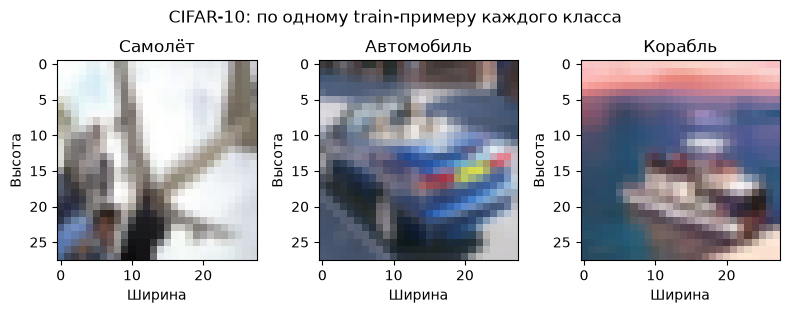

In [25]:
class CifarSubset(Dataset):
    def __init__(self,source,indices,label_map):
        self.source=source;self.indices=list(indices);self.label_map=dict(label_map)
    def __len__(self):return len(self.indices)
    def __getitem__(self,index):
        image,label=self.source[self.indices[index]]
        return image,self.label_map[label]

cifar_train=CifarSubset(cifar_train_source,cifar_indices["train"],label_map)
cifar_valid=CifarSubset(cifar_train_source,cifar_indices["valid"],label_map)
cifar_test=CifarSubset(cifar_test_source,cifar_indices["test"],label_map)
cifar_train_loader=DataLoader(cifar_train,batch_size=128,shuffle=True,num_workers=0,
    generator=torch.Generator().manual_seed(SEED))
cifar_valid_loader=DataLoader(cifar_valid,batch_size=256,shuffle=False,num_workers=0)
cifar_test_loader=DataLoader(cifar_test,batch_size=256,shuffle=False,num_workers=0)
images,labels=next(iter(cifar_train_loader))
assert images.shape==(128,3,28,28) and labels.shape==(128,)
assert images.dtype==torch.float32 and labels.dtype==torch.int64
assert set(labels.tolist())<=set(range(3))
print("Пакет:",images.shape,images.dtype,"Метки:",labels.shape,labels.dtype)
fig,axes=plt.subplots(1,3,figsize=(8,3))
for k,ax in enumerate(axes):
    i=next(i for i in range(len(cifar_train)) if cifar_train[i][1]==k)
    image,label=cifar_train[i]
    ax.imshow((image*.5+.5).permute(1,2,0).clamp(0,1).numpy())
    ax.set(title=class_names[label],xlabel="Ширина",ylabel="Высота")
plt.suptitle("CIFAR-10: по одному train-примеру каждого класса")
plt.tight_layout();savefig("13_cifar_examples.png")

### 7.2. CNN и пять эпох

Два блока Conv2d → BatchNorm2d → ReLU → MaxPool2d и Linear на три логита. Размеры: 3×28×28 → 8×14×14 → 16×7×7 → 784 → 3. Архитектура и число эпох фиксируются до test.

Sequential(
  (0): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (5): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Flatten(start_dim=1, end_dim=-1)
  (9): Linear(in_features=784, out_features=3, bias=True)
) Параметров: 3771


,layer,shape,parameters
0,Conv2d,"(1, 8, 28, 28)",216
1,BatchNorm2d,"(1, 8, 28, 28)",16
2,ReLU,"(1, 8, 28, 28)",0
3,MaxPool2d,"(1, 8, 14, 14)",0
4,Conv2d,"(1, 16, 14, 14)",1152
5,BatchNorm2d,"(1, 16, 14, 14)",32
6,ReLU,"(1, 16, 14, 14)",0
7,MaxPool2d,"(1, 16, 7, 7)",0
8,Flatten,"(1, 784)",0
9,Linear,"(1, 3)",2355


cifar {'epoch': 1, 'train_loss': 0.8315313537915547, 'valid_accuracy': 0.5155555555555555, 'train_seconds': 2.211751599999843}


cifar {'epoch': 2, 'train_loss': 0.6473500201967027, 'valid_accuracy': 0.71, 'train_seconds': 2.1638567999998486}


cifar {'epoch': 3, 'train_loss': 0.6159839436213176, 'valid_accuracy': 0.7266666666666667, 'train_seconds': 2.1570811999999933}


cifar {'epoch': 4, 'train_loss': 0.5579723041322496, 'valid_accuracy': 0.7511111111111111, 'train_seconds': 2.183330500000011}


cifar {'epoch': 5, 'train_loss': 0.5283046567175124, 'valid_accuracy': 0.76, 'train_seconds': 2.1815699999997378}


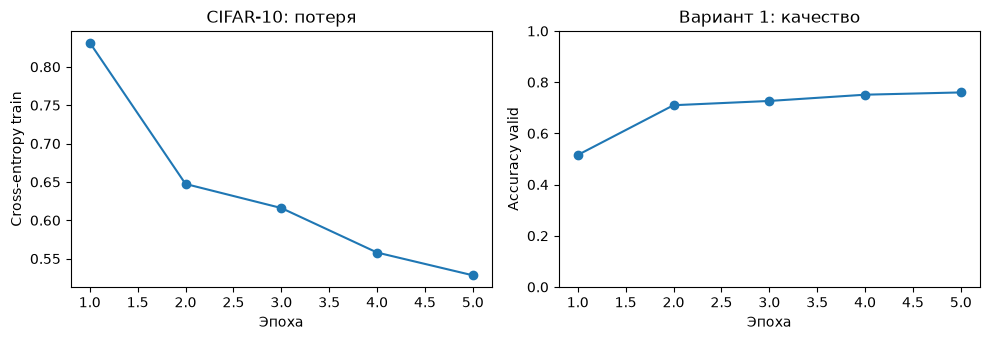

In [26]:
def make_cifar_model():
    return nn.Sequential(
        nn.Conv2d(3,8,3,padding=1,bias=False),nn.BatchNorm2d(8),nn.ReLU(),nn.MaxPool2d(2),
        nn.Conv2d(8,16,3,padding=1,bias=False),nn.BatchNorm2d(16),nn.ReLU(),nn.MaxPool2d(2),
        nn.Flatten(),nn.Linear(16*7*7,3))
torch.manual_seed(SEED)
cifar_model=make_cifar_model().to(device)
print(cifar_model,"Параметров:",params(cifar_model))
assert params(cifar_model)==3771
cifar_model.eval();current=torch.zeros(1,3,28,28,device=device);shapes=[]
with torch.no_grad():
    for layer in cifar_model:
        current=layer(current)
        shapes.append(dict(layer=type(layer).__name__,shape=str(tuple(current.shape)),parameters=params(layer)))
display(pd.DataFrame(shapes))
with torch.no_grad():assert cifar_model(images.to(device)).shape==(len(images),3)
cifar_history=fit(cifar_model,cifar_train,cifar_valid_loader,"cifar")
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
axes[0].plot(cifar_history.epoch,cifar_history.train_loss,"o-")
axes[0].set(xlabel="Эпоха",ylabel="Cross-entropy train",title="CIFAR-10: потеря")
axes[1].plot(cifar_history.epoch,cifar_history.valid_accuracy,"o-")
axes[1].set(xlabel="Эпоха",ylabel="Accuracy valid",ylim=(0,1),title=f"Вариант {variant}: качество")
plt.tight_layout();savefig("14_cifar_history.png")

### 7.3. Test и первые три ошибки

В итоговом проходе — eval и no_grad, без backward/step. Берём состояние пятой эпохи, а не подбираем эпоху по test.

cifar {'accuracy': 0.7744444444444445, 'macro_f1': 0.7746268504057009, 'test_size': 900, 'parameters': 3771}


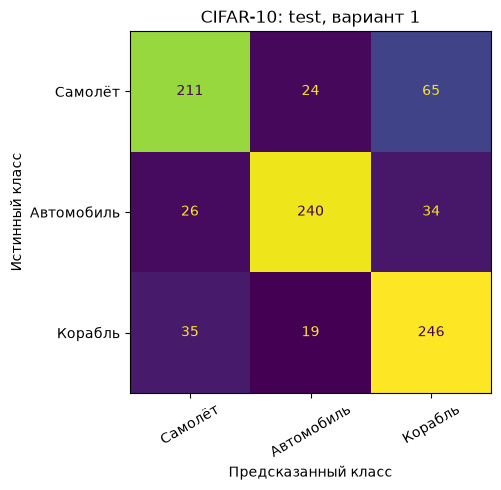

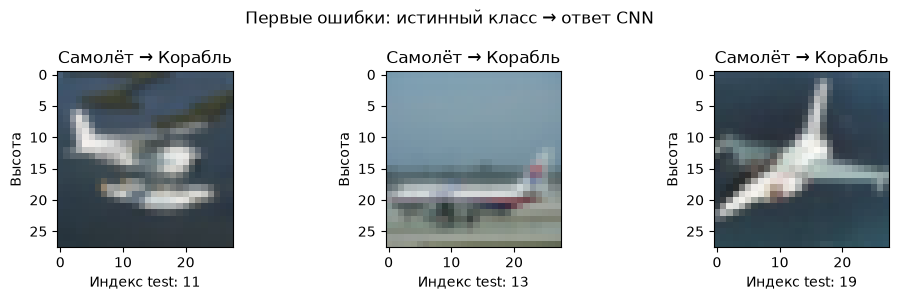

Сохранены веса, параметры опыта, индексы и метрики. После загрузки логиты совпали.


In [27]:
cifar_answers,cifar_predictions,cifar_probability,cifar_metrics=assess(
    cifar_model,cifar_test_loader,"cifar",class_names)
assert len(cifar_answers)==900
confusion_plot(cifar_answers,cifar_predictions,class_names,
    f"CIFAR-10: test, вариант {variant}","15_cifar_confusion.png")
cifar_error_indices=np.flatnonzero(cifar_answers!=cifar_predictions)[:3]
error_rows=[]
if len(cifar_error_indices):
    fig,axes=plt.subplots(1,len(cifar_error_indices),figsize=(10,3),squeeze=False)
    for ax,index in zip(axes.flat,cifar_error_indices):
        image,label=cifar_test[int(index)];pred=int(cifar_predictions[index])
        ax.imshow((image*.5+.5).permute(1,2,0).clamp(0,1).numpy())
        ax.set(title=f"{class_names[label]} → {class_names[pred]}",
            xlabel=f"Индекс test: {index}",ylabel="Высота")
        error_rows.append(dict(test_position=int(index),source_index=cifar_indices["test"][int(index)],
            label=int(label),prediction=pred,confidence=float(cifar_probability[index,pred])))
    plt.suptitle("Первые ошибки: истинный класс → ответ CNN")
    plt.tight_layout();savefig("16_cifar_errors.png")
else:print("Ошибок на test нет.")
pd.DataFrame(error_rows).to_csv(OUT/"cifar_error_examples.csv",index=False)
restored=make_cifar_model().to(device)
restored.load_state_dict(torch.load(OUT/"cifar_weights.pt",map_location=device,weights_only=True))
cifar_model.eval();restored.eval()
probe=next(iter(cifar_test_loader))[0][:16].to(device)
with torch.no_grad():assert torch.allclose(cifar_model(probe),restored(probe),atol=1e-6)
config=dict(variant=variant,original_classes=selected_classes,class_names=class_names,
    seed=SEED,split_sizes={k:len(v) for k,v in cifar_indices.items()},
    per_class=dict(train=1500,valid=300,test=300),image_shape=[3,28,28],
    transform="Resize 28x28, ToTensor, Normalize(mean=.5,std=.5) per channel",
    architecture="Conv3-8-BN-ReLU-Pool2, Conv8-16-BN-ReLU-Pool2, Flatten, Linear784-3",
    parameters=params(cifar_model),optimizer="Adam",lr=.001,batch_size=128,epochs=5,
    final_epoch=5,environment=environment,test=cifar_metrics,
    reload_logits_match=True)
(OUT/"cifar_config.json").write_text(json.dumps(config,ensure_ascii=False,indent=2),encoding="utf-8")
print("Сохранены веса, параметры опыта, индексы и метрики. После загрузки логиты совпали.")

**Вывод:** нормировка для рисунка обращается выражением image×0,5+0,5; модель получает нормированный тензор. Признаки и правила предобработки должны совпадать при повторном применении сохранённых весов. Метрики и конкретные ошибки приведены ниже после расчёта.

## 8. Итоговые результаты

**Дицель Н.С., ИКБО-11-23.** 07.11.2026. Проверил: ст. преподаватель Приходько Н.А.

**Цель:** проверить вычисления PyTorch, обучить классификаторы MNIST, BloodMNIST и CIFAR-10. **Окружение:** Python 3.12.10, PyTorch 2.15.0+cpu, torchvision 0.29.2+cpu, cpu, 2 потока CPU. Seed=42, Adam(lr=0,001), batch=128, пять эпох. Test не используется для выбора архитектуры или эпохи.

### 1. Тензоры и шаг обучения

- Проверены арифметика, индексация, broadcasting, reshape/permute и общая память from_numpy.
- Ручное XWᵀ+b совпало с Linear; Linear(3,2) содержит 3×2+2=8 параметров.
- Два слоя без активации сведены в один. ReLU позволила аппроксимировать x².
- Ручные градиенты MSE и шаг SGD совпали с PyTorch; потеря уменьшилась.
- CrossEntropyLoss совпала с ручным расчётом; на вход подаются логиты.
- Проверены ручная свёртка и BatchNorm в train/eval. Pooling обучаемых весов не имеет.

**Вывод:** формы и режим вычисления важны отдельно от значений. zero_grad очищает градиенты, backward вычисляет их, step обновляет веса. Dataset возвращает один объект; DataLoader формирует пакеты.

### 2. MNIST: линейная модель

Использованы 10 000 train и 2 000 valid из исходного train; проверено отсутствие общих индексов. Официальный test — 10 000 изображений. Модель Flatten → Linear(784,10), **7850 параметров**.

После пятой эпохи: **accuracy test 89.87%**, **macro-F1 0.8975**. Потеря train изменилась с 1.3562 до 0.4253; accuracy valid — с 83.90% до 89.40%.

**Вывод:** линейное правило по пикселям уже различает большинство цифр, но не строит локальные признаки. Веса выхода «3» визуализированы в блокноте; это вклад пикселя в логит, а не вероятность.



### 3. BloodMNIST: линейная модель и CNN

Общий train: по 600 изображений восьми классов, всего 4 800. Официальные valid — 1 712 и test — 3 421 сохранены целиком. Обе модели используют RGB 28×28 и одинаковую нормировку, порядок train-пакетов и число эпох.

CNN: Conv(3→8) → BN → ReLU → Pool → Conv(8→16) → BN → ReLU → Pool → Flatten → Linear(784→8). Проверено совпадение ответа через вектор признаков с полным проходом.

| Модель | Accuracy test | Macro-F1 test | Параметров | Обучение 5 эпох, с | Пакет 64, мс |
| --- | --- | --- | --- | --- | --- |
| Линейная | 0.7357 | 0.7101 | 18824 | 5.4983 | 0.1718 |
| CNN | 0.8468 | 0.8287 | 7696 | 10.5268 | 6.7133 |

**Вывод:** CNN увеличила accuracy на 11.11 п.п. при меньшем числе параметров (7696 против 18824). На этом CPU пакет 64 CNN обрабатывает в 39.1 раза дольше: свёртки выполняют много операций над картами.

Время — медиана трёх повторов после прогрева; чтение и перенос данных исключены. Чаще всего CNN ошибалась в направлении **Незрелые гранулоциты → Базофил (90 объектов)**. Число параметров, качество и скорость нужно оценивать отдельно.





### 4. Самостоятельная часть: CIFAR-10, вариант №1

Выбраны **самолёт, автомобиль, корабль**; исходные коды [0, 1, 8] заменены на 0,1,2 в том же порядке. Правило назначения по группе/зачётке в материалах отсутствует; использован вариант №1 из заготовки.

Состав: **4 500 train / 900 valid / 900 test**. На класс — 1 500/300/300; train и valid взяты из исходного train без пересечения, test — из официального test. Индексы сохранены. Ошибочные упоминания 100 test в заготовке заменены требованием методички — 300.

Предобработка: Resize 32→28, ToTensor, Normalize(mean=0,5; std=0,5) по каналам, однократно. Пакет — (N,3,28,28), метки int64. CNN: два блока 3→8→16, pooling до 7×7, Flatten 784, Linear на три логита; **3771 параметр**.

| epoch | train_loss | valid_accuracy | train_seconds |
| --- | --- | --- | --- |
| 1 | 0.8315 | 0.5156 | 2.2118 |
| 2 | 0.6474 | 0.7100 | 2.1639 |
| 3 | 0.6160 | 0.7267 | 2.1571 |
| 4 | 0.5580 | 0.7511 | 2.1833 |
| 5 | 0.5283 | 0.7600 | 2.1816 |

Параметры пятой эпохи: **accuracy test 77.44%**, **macro-F1 0.7746**. Постоянный ответ на сбалансированном test даёт 33,33%. Самый большой прирост valid между эпохами — **1→2: 19.44 п.п.**





**Ошибки:** наиболее частое направление — **Самолёт → Корабль (65 объектов)**. Ниже показаны первые три неверных ответа, без отбора по красивому примеру. Подпись содержит исходный класс и предсказание; для показа нормировка обращена image×0,5+0,5.

Малая модель обучалась только пять эпох на части корпуса; результат относится к этому разбиению. График valid описывает процесс обучения, итоговый test не использовался для подбора.



**Сохранено:** выполненный блокнот, четыре state_dict, истории, метрики по классам, прогнозы, индексы разбиений, параметры опыта и рисунки. Для CIFAR-10 после загрузки весов логиты на 16 фиксированных test-примерах совпали. В проходах оценки веса и буферы BatchNorm не менялись.

**Ответы на вопросы:** отдельный файл «Ответы_на_вопросы_7.md» — 15 полных вопросов лекции №7 (слайды 70–71) и 7 вопросов раздела 8 практики, с краткими ответами.

Источники: выданные методичка и лекция №7; [PyTorch](https://pytorch.org/get-started/locally/), [MedMNIST](https://medmnist.com/), [CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html).